## EDA для датасета prices_daily.csv

Подготовка исходных данных

In [1]:
# Выполнить один раз при отсутствии prices_daily.csv.
# Запуск предполагает, что текущая директория — notebooks/.

# !uv run --project .. --group data python ../scripts/download_prices.py

In [2]:
# Проверка исходных данных
from pathlib import Path

prices_path = Path("../data/raw/prices_daily.csv")

if not prices_path.exists():
    raise FileNotFoundError(
        "Не найден prices_daily.csv. "
        "Сначала выполните ячейку загрузки данных выше."
    )

Загрузка данных

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

prices = pd.read_csv(prices_path)

In [4]:
prices.head()

,trade_date,boardid,secid,open,high,low,close,volume,value,numtrades
0,2018-01-03,TQBR,AFKS,12.485,12.550,12.260,12.350,20687500,256119052.0,5071
1,2018-01-04,TQBR,AFKS,12.365,12.465,12.240,12.385,14880200,183676750.0,4362
2,2018-01-05,TQBR,AFKS,12.385,12.420,12.220,12.390,11072000,136535338.0,3666
3,2018-01-09,TQBR,AFKS,12.545,12.840,12.505,12.715,30905600,393081866.5,9167
4,2018-01-10,TQBR,AFKS,12.785,12.835,12.520,12.700,11774300,148739015.5,4446


Информация по таблице:
|Столбец|Тип|Что это|
|---|---|---|
|`trade_date`|str|торговая дата (выходные и праздники не добавляем)|
|`boardid`|str|режим торгов|
|`secid`|str|тикер|
|`open`, `high`, `low`, `close`|float|цены за день, руб.|
|`volume`|int|число бумаг|
|`value`|float|оборот за день, руб.|
|`numtrades`|int|число сделок (если источник отдаёт)|


In [5]:
size = prices.shape
print('В датасете:')
print(f'cтрок - {size[0]}.')
print(f'cтолбцов - {size[1]}.')

В датасете:
cтрок - 77438.
cтолбцов - 10.


In [6]:
prices.dtypes

trade_date     object
boardid        object
secid          object
open          float64
high          float64
low           float64
close         float64
volume          int64
value         float64
numtrades       int64
dtype: object

**Примечание**: Мы видим что тип objects у нас в столбцах trade_data(торговый день), boardid(режим торгов), secid(тикер), остальные столбцы имеют численные значения.

In [7]:
print(f'Количество уникальных тикеров в датасете - {len(prices['secid'].unique())}')

Количество уникальных тикеров в датасете - 44


In [8]:
prices['trade_date'] = pd.to_datetime(prices['trade_date']) # переводим дату в тип datetime
print(f'Минимальная дата - {prices['trade_date'].min()}')
print(f'Максимальная дата - {prices['trade_date'].max()}')

Минимальная дата - 2018-01-03 00:00:00
Максимальная дата - 2026-11-02 00:00:00


In [9]:
prices.groupby('secid').size().sort_values()

secid
DOMRF     241
RAGR      436
CNRU      442
X5        463
T         490
HEAD      564
YDEX      593
SVCB      733
UGLD      750
POSI     1238
VKCO     1241
RENI     1279
OZON     1510
MDMG     1521
FLOT     1543
ENPG     1702
MAGN     2239
LKOH     2239
IRAO     2239
GMKN     2239
GAZP     2239
NLMK     2239
MTSS     2239
MOEX     2239
PLZL     2239
PHOR     2239
ALRS     2239
CHMF     2239
CBOM     2239
BSPB     2239
AFKS     2239
AFLT     2239
SBERP    2239
SBER     2239
RUAL     2239
RTKM     2239
ROSN     2239
NVTK     2239
SNGS     2239
SNGSP    2239
TRNFP    2239
TATNP    2239
TATN     2239
VTBR     2239
dtype: int64

**Примечание**: Видим что некоторые тикеры имеют меньше строк, а какие-то больше, это связано с тем что некоторые компании начали торговаться на MOEX позже остальных или произошла редомиляция компаний (переход из иностранного резиденства в отечественный), остановка торгов и т.д. В пример можно привести такие компании как Яндекс(YDEX) и X5 Retail Group(X5) которые прошли процесс редомиляции.

In [10]:
print(f'В датасете {prices.duplicated(subset=['trade_date', 'boardid', 'secid']).sum()} дубликатов')

В датасете 0 дубликатов


### Пропуски и полнота данных prices_daily.csv

In [11]:
print('Количество пропущенных значений по столбцам')
prices.isna().sum() # количество пропущенных значений в каждом столбце

Количество пропущенных значений по столбцам


trade_date      0
boardid         0
secid           0
open          833
high          833
low           833
close         833
volume          0
value           0
numtrades       0
dtype: int64

In [12]:
print('Процент пропущенных значений по столбцам')
(prices.isna().sum() / len(prices)) * 100

Процент пропущенных значений по столбцам


trade_date    0.000000
boardid       0.000000
secid         0.000000
open          1.075699
high          1.075699
low           1.075699
close         1.075699
volume        0.000000
value         0.000000
numtrades     0.000000
dtype: float64

**Примечание**: По таблице видно что пропущенные значения есть в столбцах open, high, low, close. Процент пропущенных значений в этих столбцах ~ 1%

In [13]:
universe_path = Path("../config/universe.csv")

universe = pd.read_csv(universe_path) # Добавляем таблицу universe.csv

In [14]:
universe.head()

,secid,shortname,boardid,sector,is_pref,snapshot_date
0,AFKS,Система ао,TQBR,финансы,0,2026-11-02
1,AFLT,Аэрофлот,TQBR,транспорт,0,2026-11-02
2,ALRS,АЛРОСА ао,TQBR,металлы и добыча,0,2026-11-02
3,BSPB,БСП ао,TQBR,финансы,0,2026-11-02
4,CBOM,МКБ ао,TQBR,финансы,0,2026-11-02


In [15]:
print('Сопоставимость secid из prices_daily.csv и universe.csv - ', end='')
print(set(prices['secid'].unique()) == set(universe['secid'].unique()))

Сопоставимость secid из prices_daily.csv и universe.csv - True


In [16]:
prices[['open', 'high', 'low', 'close']].isna().all(axis=1).sum()

np.int64(833)

**Примечание**: Получается что все пропуски у нас во всех четырех столбцах одновременно. Соответственно можно выдвинуть гипотезу, что это был промежуток времени когда торги были остановлены на определенный промежуток времени.

In [17]:
prices[prices['close'].isna()].head(10)

,trade_date,boardid,secid,open,high,low,close,volume,value,numtrades
1015,2022-01-07,TQBR,AFKS,NaN,NaN,NaN,NaN,0,0.0,0
1048,2022-02-23,TQBR,AFKS,NaN,NaN,NaN,NaN,0,0.0,0
1051,2022-02-28,TQBR,AFKS,NaN,NaN,NaN,NaN,0,0.0,0
1052,2022-03-01,TQBR,AFKS,NaN,NaN,NaN,NaN,0,0.0,0
1053,2022-03-02,TQBR,AFKS,NaN,NaN,NaN,NaN,0,0.0,0
1054,2022-03-03,TQBR,AFKS,NaN,NaN,NaN,NaN,0,0.0,0
1055,2022-03-04,TQBR,AFKS,NaN,NaN,NaN,NaN,0,0.0,0
1056,2022-03-09,TQBR,AFKS,NaN,NaN,NaN,NaN,0,0.0,0
1057,2022-03-10,TQBR,AFKS,NaN,NaN,NaN,NaN,0,0.0,0
1058,2022-03-11,TQBR,AFKS,NaN,NaN,NaN,NaN,0,0.0,0


**Примечание**: Видно что там где OHLC == NaN volume, value, numtrades равны нулю, из этого следует что торгов в эти дни не было. 

In [18]:
prices[prices['close'].isna()].groupby('secid').size().sort_values(ascending=False)

secid
OZON     56
VKCO     44
CNRU     39
MDMG     38
HEAD     29
RUAL     22
TRNFP    22
VTBR     22
GMKN     22
PLZL     21
RENI     21
FLOT     20
BSPB     20
ENPG     20
POSI     20
AFKS     18
CBOM     18
CHMF     18
AFLT     18
ALRS     18
MAGN     18
LKOH     18
IRAO     18
GAZP     18
PHOR     18
MTSS     18
NLMK     18
NVTK     18
MOEX     18
SBER     18
ROSN     18
RTKM     18
SNGSP    18
SNGS     18
SBERP    18
TATN     18
TATNP    18
YDEX     12
UGLD      5
T         4
dtype: int64

**Примечание**: Больше всего пропусков у нас приходится на тикеры OZON, VKCO, CNRU, MDMG.

In [19]:
len(prices[prices['numtrades'] == 0])

833

**Примечание**: По выводу видно что там где numtrades = 0 число строк равно так же 833.

In [20]:
missing_ohlc = prices[["open", "high", "low", "close"]].isna().all(axis=1)
zero_trades = prices["numtrades"] == 0
print(f'Совпадение строк с пропущенными OHLC и строки где количество сделок равно нулю - {all(missing_ohlc == zero_trades)}')


Совпадение строк с пропущенными OHLC и строки где количество сделок равно нулю - True


**Примечание**: Из этого мы можем сделать вывод что там где пропущены OHLC не было сделок.

In [21]:
prices['zero_trades'] = zero_trades # добавляем столбец, который показывает есть ли нулевое количество сделок в этот день

In [22]:
zero_trades_count = prices[['trade_date', 'zero_trades']].groupby('trade_date').sum()

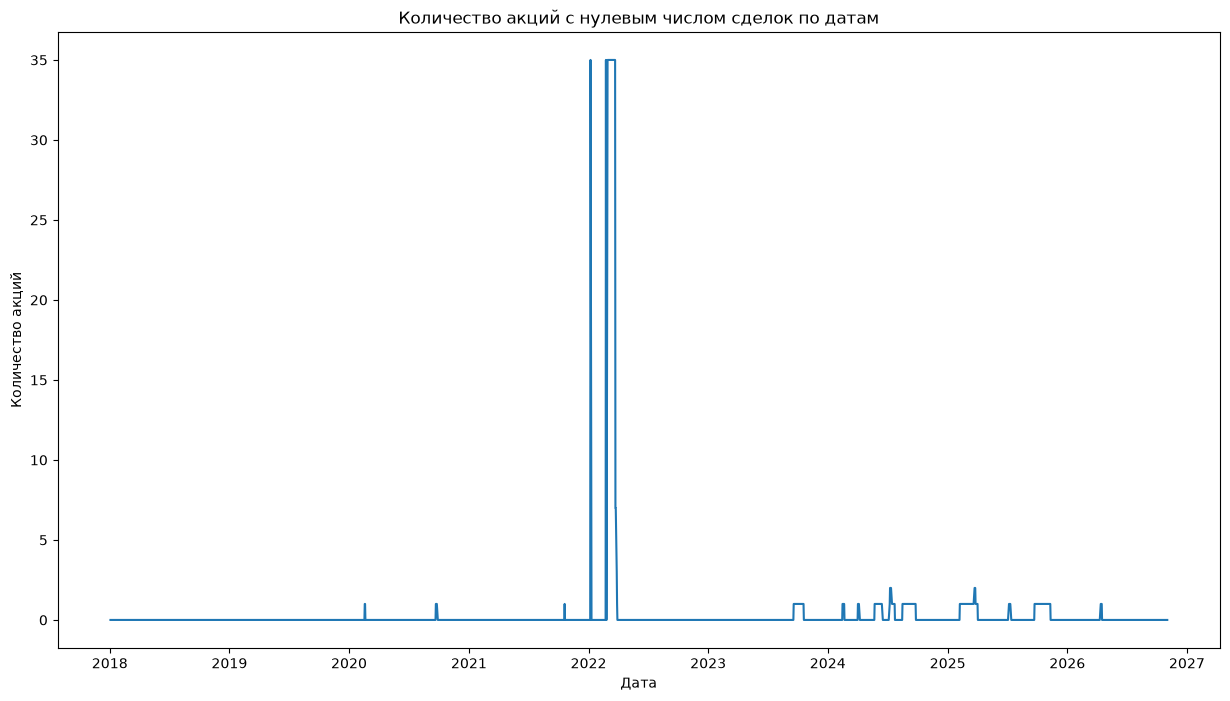

In [23]:
fig, ax = plt.subplots(figsize=(15, 8))

sns.lineplot(
    data=zero_trades_count,
    x=zero_trades_count.index,
    y='zero_trades',
    ax=ax
)

ax.set_title('Количество акций с нулевым числом сделок по датам')
ax.set_xlabel('Дата')
ax.set_ylabel('Количество акций')
plt.show()


**Примечание**: Исследуя график мы можем обратить внимание, что основной рост количества акций по которым не было сделок случился в 2022 году (примерно до 35 одновременно). Это может быть связано с приостановкой торгов на Московской бирже. В последующих годах встречаются отдельные небольшие всплески.

In [24]:
# 19 дат с максимальным числом акций без сделок
zero_trades_count.sort_values(
    by=['zero_trades'],
    ascending=False
).head(19)

,zero_trades
trade_date,
2022-03-01,35
2022-03-03,35
2022-03-04,35
2022-03-09,35
2022-03-10,35
2022-03-11,35
2022-03-14,35
2022-03-15,35
2022-03-02,35


In [25]:
# проверка положительности цен
for p in ('open', 'high', 'low', 'close'):
    print((prices[p] <= 0).sum()) # проверка на булево значение, есть ли такие строки где p меньше либо равно нулю

0
0
0
0


In [26]:
# проверка неотрицательности value, volume и numtrades
for p in ('value', 'volume', 'numtrades'):
    print((prices[p] < 0).sum()) # проверка на булево значение, есть ли такие строки где p меньше нуля

0
0
0


In [27]:
valid_prices = prices.dropna(
    subset=['open', 'high', 'low', 'close']
)
valid_prices.head()

,trade_date,boardid,secid,open,high,low,close,volume,value,numtrades,zero_trades
0,2018-01-03,TQBR,AFKS,12.485,12.550,12.260,12.350,20687500,256119052.0,5071,False
1,2018-01-04,TQBR,AFKS,12.365,12.465,12.240,12.385,14880200,183676750.0,4362,False
2,2018-01-05,TQBR,AFKS,12.385,12.420,12.220,12.390,11072000,136535338.0,3666,False
3,2018-01-09,TQBR,AFKS,12.545,12.840,12.505,12.715,30905600,393081866.5,9167,False
4,2018-01-10,TQBR,AFKS,12.785,12.835,12.520,12.700,11774300,148739015.5,4446,False


In [28]:
result = (
    (valid_prices['low'] <= valid_prices['open']).all()
    and
    (valid_prices['open'] <= valid_prices['high']).all()
    and
    (valid_prices['low'] <= valid_prices['close']).all()
    and
    (valid_prices['close'] <= valid_prices['high']).all()
)

print(result)

True


**Примечание**: проверили условие, что 

$low \leq open \leq high$

$low \leq close \le high$

### Доходности

In [29]:
prices.head()

,trade_date,boardid,secid,open,high,low,close,volume,value,numtrades,zero_trades
0,2018-01-03,TQBR,AFKS,12.485,12.550,12.260,12.350,20687500,256119052.0,5071,False
1,2018-01-04,TQBR,AFKS,12.365,12.465,12.240,12.385,14880200,183676750.0,4362,False
2,2018-01-05,TQBR,AFKS,12.385,12.420,12.220,12.390,11072000,136535338.0,3666,False
3,2018-01-09,TQBR,AFKS,12.545,12.840,12.505,12.715,30905600,393081866.5,9167,False
4,2018-01-10,TQBR,AFKS,12.785,12.835,12.520,12.700,11774300,148739015.5,4446,False


In [30]:
returns_df = prices.sort_values(
    by=['secid', 'trade_date']
).copy()

returns_df['prev_close'] = (
    returns_df.groupby('secid')['close'].shift(1)
) # добавляем столбец с предыдущим закрытием
returns_df['log_return'] = np.log(returns_df['close'] / returns_df['prev_close']) # добавляем столбец с расчитанной ежедневной log доходностью (изменение между соседними записями одной бумаги)

In [31]:
returns_df[returns_df['secid'] == 'SBER'].head(7)

,trade_date,boardid,secid,open,high,low,close,volume,value,numtrades,zero_trades,prev_close,log_return
55256,2018-01-03,TQBR,SBER,226.88,232.70,226.35,231.90,34549620,7.965493e+09,40597,False,NaN,NaN
55257,2018-01-04,TQBR,SBER,232.13,239.50,231.00,238.80,53598520,1.263668e+10,62294,False,231.90,0.029320
55258,2018-01-05,TQBR,SBER,238.89,239.95,236.70,238.60,31579190,7.522345e+09,39468,False,238.80,-0.000838
55259,2018-01-09,TQBR,SBER,239.03,243.76,239.01,240.40,53172330,1.283838e+10,51959,False,238.60,0.007516
55260,2018-01-10,TQBR,SBER,240.40,241.25,237.06,237.76,39371720,9.385277e+09,43751,False,240.40,-0.011042
55261,2018-01-11,TQBR,SBER,237.76,240.88,235.21,239.00,43067630,1.027451e+10,55105,False,237.76,0.005202
55262,2018-01-12,TQBR,SBER,238.92,239.00,236.05,237.75,30895860,7.339742e+09,36540,False,239.00,-0.005244


In [32]:
returns_df['abs_log_return'] = returns_df['log_return'].abs() # добавляем столбец с модулем log доходности

In [33]:
returns_df.sort_values(by='abs_log_return', ascending=False).head(15)

,trade_date,boardid,secid,open,high,low,close,volume,value,numtrades,zero_trades,prev_close,log_return,abs_log_return
11051,2026-04-13,TQBR,CBOM,5.1490,8.292,5.0040,7.895,766152500,5.941001e+09,168797,False,5.129,0.431319,0.431319
18494,2022-06-30,TQBR,GAZP,299.5000,310.820,200.0000,207.000,308032430,6.971632e+10,774022,False,297.650,-0.363200,0.363200
47188,2026-07-24,TQBR,RAGR,70.2200,99.580,68.5200,98.960,69857744,6.349456e+09,220549,False,70.360,0.341091,0.341091
45655,2022-03-29,TQBR,POSI,862.0000,1095.800,862.0000,1095.800,327041,3.448577e+08,21180,False,783.600,0.335341,0.335341
45502,2026-07-08,TQBR,PLZL,1825.0000,1825.000,1330.2000,1345.000,16168221,2.300338e+10,388242,False,1828.000,-0.306828,0.306828
7767,2022-02-25,TQBR,BSPB,50.0200,70.400,50.0200,66.980,1204960,7.770738e+07,5160,False,50.000,0.292371,0.292371
33952,2022-03-30,TQBR,MTSS,177.1500,235.000,177.1500,233.000,3505910,7.360669e+08,22340,False,174.700,0.287968,0.287968
39941,2022-03-31,TQBR,OZON,1100.0000,1438.000,1090.0000,1425.000,1251949,1.646420e+09,67098,False,1070.000,0.286513,0.286513
72950,2022-02-21,TQBR,VKCO,555.0000,580.600,399.8000,420.000,10782171,5.128980e+09,151714,False,559.200,-0.286252,0.286252
74142,2026-11-02,TQBR,VKCO,164.1000,219.950,163.1000,215.350,242183949,4.815523e+10,777857,False,163.700,0.274229,0.274229


**Примечание**: По отсортированной таблице мы видим крупные изменения в доходности, причем большая часть из них за 2022 год. Эти изменения нельзя сразу считать за выбросы, так как по ним могли проходить реальные корпоративные события, такие как дивидендный гэп, сплит, так же решение о не выплате дивидендов и т.д.

### Расчет target_vol_21d (Основной)

В соответствии с первоначальным планом проекта целевая переменная определяется как логарифм среднеквадратичной дневной логарифмической доходности (RMS) за следующие 21 торговое наблюдение.

Формула:

$
target\_vol\_21d(t) =
\ln\left(\sqrt{\frac{1}{21}\sum_{k=1}^{21}r_{t+k}^{2}}\right)
$

где $r_t = \ln(C_t / C_{t-1})$ — дневная логарифмическая доходность акции.

Особенности расчёта:
1. RMS характеризует величину колебаний доходности, учитывая как положительные, так и отрицательные изменения.
2. Логарифмирование переводит показатель на логарифмическую шкалу.
3. Используются только будущие доходности (t+1,\ldots,t+21).
4. Расчёт выполняется отдельно для каждой акции.
5. При недостаточной длине окна или наличии пропусков таргет принимает значение NaN.
6. При нулевой RMS также используется NaN, чтобы избежать значения -inf.

Интерпретация: отрицательные значения target_vol_21d допустимы и не означают отрицательный риск. Показатель находится в логарифмической шкале и не интерпретируется непосредственно как процент годовой волатильности.

In [34]:
HORIZON = 21

returns_df = returns_df.sort_values(
    ["secid", "trade_date"]
).copy()

# Средний квадрат дневных логарифмических доходностей
# за следующие 21 наблюдение
future_mean_r2 = (
    returns_df.groupby("secid")["log_return"]
    .transform(
        lambda x: (
            x.pow(2)
            .rolling(
                window=HORIZON,
                min_periods=HORIZON
            )
            .mean()
            .shift(-HORIZON)
        )
    )
)

# Основной таргет: ln(RMS)
returns_df["target_vol_21d"] = np.log(
    np.sqrt(future_mean_r2.where(future_mean_r2 > 0))
)

### Расчет target_vol_21d_std_ann (Дополнительный)

Для сравнения рассчитана реализованная волатильность за следующие 21 торговое наблюдение через выборочное стандартное отклонение логарифмических доходностей, приведённое к годовой шкале.

$$
\text{target\_vol\_21d}(t) = \sqrt{252} \cdot \text{std}(r_{t+1}, \dots, r_{t+21})
$$
Где:
- \(i\) — конкретная акция;
- \(t\) — дата, на которую формируем прогноз;
- \(r\) — дневная логарифмическая доходность;
- std — выборочное стандартное отклонение с ddof=1;
- 21 — горизонт будущих торговых дней;
- $\sqrt{252}$ — перевод волатильности в годовую шкалу.

То есть для каждой акции на дату \(t\) мы берём 21 будущую дневную логарифмическую доходность, вычисляем их выборочное стандартное отклонение и переводим результат в годовую шкалу.

В отличие от основного таргета, этот показатель выражается в привычной шкале годовой волатильности. Например, значение 0.30 соответствует 30% годовой волатильности.

Дополнительный таргет используется для сравнения и финансовой интерпретации. 

In [35]:
returns_df["target_vol_21d_std_ann"] = (
    returns_df.groupby("secid")["log_return"]
    .transform(
        lambda x: (
            x.rolling(
                window=HORIZON,
                min_periods=HORIZON
            )
            .std(ddof=1)
            .shift(-HORIZON)
        )
    )
    * np.sqrt(252)
)

In [36]:
targets = ["target_vol_21d", "target_vol_21d_std_ann"]

display(returns_df[targets].describe())

print("Пропуски:")
print(returns_df[targets].isna().sum())

print("\nБесконечные значения:")
print(np.isinf(returns_df[targets]).sum())

assert np.isfinite(returns_df[targets].dropna()).all().all()

# В конце каждой акции нет полного будущего окна
last_21 = returns_df.groupby("secid").tail(21)
assert last_21[targets].isna().all().all()

,target_vol_21d,target_vol_21d_std_ann
count,73942.000000,73942.000000
mean,-4.113225,0.289593
std,0.468046,0.149783
min,-6.818279,0.016597
25%,-4.421314,0.190596
50%,-4.116506,0.258473
75%,-3.817214,0.348523
max,-2.287141,1.649022


Пропуски:
target_vol_21d            3496
target_vol_21d_std_ann    3496
dtype: int64

Бесконечные значения:
target_vol_21d            0
target_vol_21d_std_ann    0
dtype: int64


In [37]:
print("СТАТИСТИКА ТАРГЕТА")

print(returns_df["target_vol_21d"].describe())

print(
    "Количество NaN:",
    returns_df["target_vol_21d"].isna().sum()
)

print(
    "Количество бесконечных значений:",
    np.isinf(returns_df["target_vol_21d"]).sum()
)

print(
    "Количество отрицательных значений:",
    (returns_df["target_vol_21d"] < 0).sum()
)

СТАТИСТИКА ТАРГЕТА
count    73942.000000
mean        -4.113225
std          0.468046
min         -6.818279
25%         -4.421314
50%         -4.116506
75%         -3.817214
max         -2.287141
Name: target_vol_21d, dtype: float64
Количество NaN: 3496
Количество бесконечных значений: 0
Количество отрицательных значений: 73942


**Прмечание**: В датасете присутствуют экстремальные значения будущей волатильности, требующие дополнительной проверки перед обучением.
Пропуски возникают из-за недостаточной длины будущих окон и отсутствующих доходностей внутри истории акций. Автоматическое заполнение таргета не применяется.  Расчёт основан на последовательности записей по каждой акции, без полной проверки торгового календаря.

In [38]:
returns_df.loc[
    returns_df["secid"] == "SBER",
    ["trade_date", "log_return", *targets]
].tail(25)

,trade_date,log_return,target_vol_21d,target_vol_21d_std_ann
57470,2026-09-29,0.008042,-4.700840,0.133656
57471,2026-09-30,-0.002661,-4.675938,0.140163
57472,2026-10-01,0.008217,-4.690368,0.139147
57473,2026-10-02,-0.002647,-4.603089,0.157499
57474,2026-10-05,0.022685,NaN,NaN
57475,2026-10-06,0.001596,NaN,NaN
57476,2026-10-07,0.002901,NaN,NaN
57477,2026-10-08,-0.009228,NaN,NaN
57478,2026-10-09,0.016200,NaN,NaN
57479,2026-10-12,0.000947,NaN,NaN


**Важные ограничения для EDA:**

Этот код считает следующие 21 запись по тикеру. Он корректно не допускает неполные окна и NaN внутри них, но не обнаруживает полностью отсутствующие строки за торговые даты.

Поэтому перед использованием таргета для ML необходимо отдельно проверить непрерывность торговых окон по календарю MOEX. Также остаётся ограничение по корпоративным событиям и дивидендам.

**Выводы:**
1. Данные содержат 44 акции с неодинаковой по продолжительности историей.
2. Есть 833 записи с отсутствующими OHLC и нулевым количеством сделок. Исходные значения не заполняются искусственно.
3. Строки с заполненными значениями OHLC корректны в датасете.
4. В датасете есть крупные движения цен. Их нельзя удалять автоматически, они могут показывать реальные рыночные события.
5. Рассчитана targey_vol_21d (логарифм среднеквадратичной дневной логарифмической доходности) и target_vol_21d_atd_ann (годовая реализованная волатильность) за следующие 21 наблюдение.
6. Перед применением ML моделей необходимо провести обработку корпоративных событий и торговых перерывов. 